In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("abide_merged.csv")

print("=" * 60)
print(f"SHAPE: {df.shape[0]} satır × {df.shape[1]} sütun")
print("=" * 60)

print("\n--- SÜTUN İSİMLERİ & TİPLERİ ---")
print(df.dtypes.to_string())

print("\n--- İLK 3 SATIR ---")
print(df.head(3).to_string())

print("\n--- TEMEL İSTATİSTİK (sayısal) ---")
print(df.describe().to_string())

print("\n--- SITE_ID değerleri ---")
if "SITE_ID" in df.columns:
    print(df["SITE_ID"].value_counts())

print("\n--- DX_GROUP / DX_LABEL değerleri ---")
for col in ["DX_GROUP", "DX_LABEL"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts())

SHAPE: 1035 satır × 81 sütun

--- SÜTUN İSİMLERİ & TİPLERİ ---
SUB_ID                           int64
FILE_ID                         object
DX_GROUP                         int64
AGE_AT_SCAN                    float64
SEX                              int64
SITE_ID                         object
FIQ                            float64
VIQ                            float64
PIQ                            float64
ADOS_TOTAL                     float64
HANDEDNESS_CATEGORY             object
DX_LABEL                        object
SEX_LABEL                       object
lh_bankssts                    float64
lh_caudalanteriorcingulate     float64
lh_caudalmiddlefrontal         float64
lh_cuneus                      float64
lh_entorhinal                  float64
lh_fusiform                    float64
lh_inferiorparietal            float64
lh_inferiortemporal            float64
lh_isthmuscingulate            float64
lh_lateraloccipital            float64
lh_lateralorbitofrontal        float64
l

# EDA — ABIDE Dataset
Analysis of distributions, missing data, and group differences.

## 1. Missing Data Analysis

Columns with missing values:
                             count   pct
ADOS_TOTAL                     643  62.1
HANDEDNESS_CATEGORY            276  26.7
VIQ                            161  15.6
PIQ                            143  13.8
FIQ                             34   3.3
rh_posteriorcingulate            2   0.2
rh_entorhinal                    1   0.1
rh_temporalpole                  1   0.1
rh_rostralanteriorcingulate      1   0.1
rh_pericalcarine                 1   0.1
rh_parahippocampal               1   0.1
rh_fusiform                      1   0.1
rh_caudalanteriorcingulate       1   0.1
rh_cuneus                        1   0.1
lh_transversetemporal            1   0.1
lh_rostralanteriorcingulate      1   0.1
lh_medialorbitofrontal           1   0.1
lh_isthmuscingulate              1   0.1
lh_caudalanteriorcingulate       1   0.1
rh_transversetemporal            1   0.1


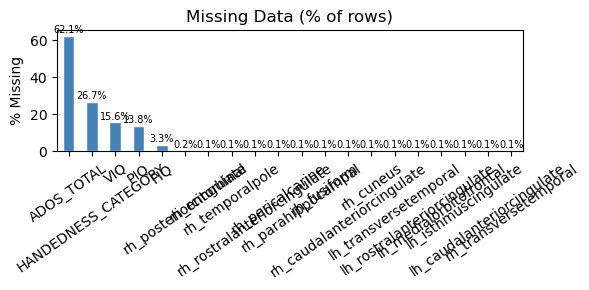

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)

print("Columns with missing values:")
print(pd.DataFrame({"count": missing, "pct": missing_pct}).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
missing_pct.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Missing Data (% of rows)")
ax.set_ylabel("% Missing")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=35)
for bar, val in zip(ax.patches, missing_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{val}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

## 2. Diagnosis & Sex Distribution

Diagnosis: {'Control': 530, 'ASD': 505}
Sex:       {'Male': 878, 'Female': 157}


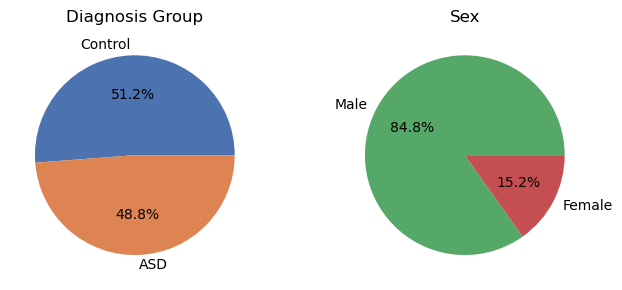

In [3]:
dx_counts = df["DX_LABEL"].value_counts()
sex_counts = df["SEX_LABEL"].value_counts() if "SEX_LABEL" in df.columns else df["SEX"].map({1: "Male", 2: "Female"}).value_counts()

print("Diagnosis:", dx_counts.to_dict())
print("Sex:      ", sex_counts.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].pie(dx_counts, labels=dx_counts.index, autopct="%1.1f%%", colors=["#4C72B0", "#DD8452"])
axes[0].set_title("Diagnosis Group")

axes[1].pie(sex_counts, labels=sex_counts.index, autopct="%1.1f%%", colors=["#55A868", "#C44E52"])
axes[1].set_title("Sex")

plt.tight_layout()
plt.show()

## 3. Age Distribution by Diagnosis Group

          count   mean   std   min   25%    50%    75%   max
DX_LABEL                                                    
ASD       505.0  17.10  8.55  7.00  11.5  14.42  19.64  64.0
Control   530.0  16.81  7.45  6.47  11.8  14.66  20.00  56.2


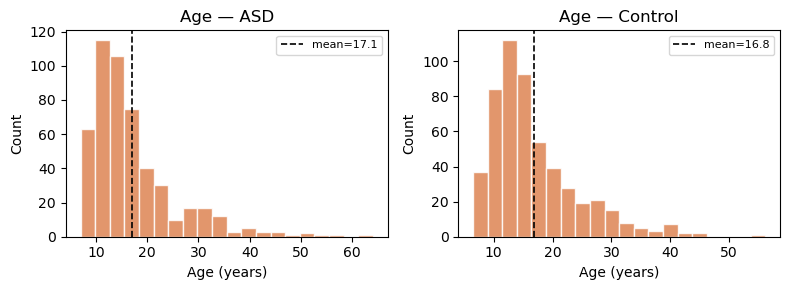

In [4]:
print(df.groupby("DX_LABEL")["AGE_AT_SCAN"].describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

for ax, (label, grp) in zip(axes, df.groupby("DX_LABEL")):
    ax.hist(grp["AGE_AT_SCAN"].dropna(), bins=20, color="#4C72B0" if label == "Autism" else "#DD8452",
            edgecolor="white", alpha=0.85)
    ax.axvline(grp["AGE_AT_SCAN"].mean(), color="black", linestyle="--", linewidth=1.2, label=f"mean={grp['AGE_AT_SCAN'].mean():.1f}")
    ax.set_title(f"Age — {label}")
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. IQ Score Distributions (FIQ, VIQ, PIQ)

IQ descriptive stats:
           FIQ      VIQ      PIQ
count  1001.00   874.00   892.00
mean   -245.11  -100.31  -142.63
std    1857.61  1436.32  1568.31
min   -9999.00 -9999.00 -9999.00
25%      97.50    97.00    96.00
50%     108.00   108.00   107.00
75%     119.00   119.00   117.00
max     148.00   180.00   155.00


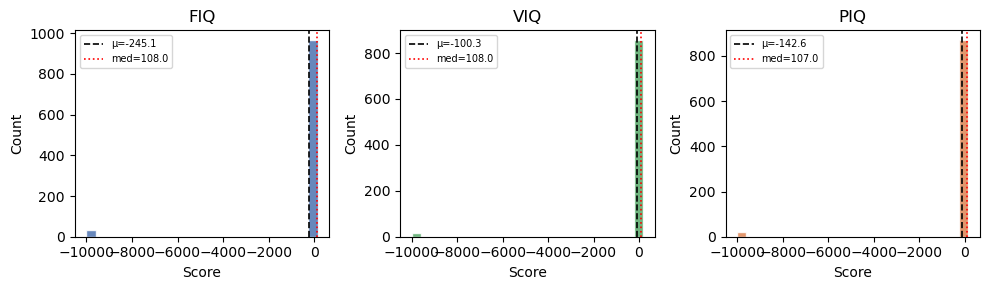

In [5]:
iq_cols = ["FIQ", "VIQ", "PIQ"]
print("IQ descriptive stats:")
print(df[iq_cols].describe().round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
colors = ["#4C72B0", "#55A868", "#DD8452"]

for ax, col, color in zip(axes, iq_cols, colors):
    data = df[col].dropna()
    ax.hist(data, bins=25, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(data.mean(), color="black", linestyle="--", linewidth=1.2, label=f"μ={data.mean():.1f}")
    ax.axvline(data.median(), color="red", linestyle=":", linewidth=1.2, label=f"med={data.median():.1f}")
    ax.set_title(col)
    ax.set_xlabel("Score")
    ax.set_ylabel("Count")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

## 5. IQ by Diagnosis Group (Boxplots)

IQ by diagnosis:
            FIQ    VIQ    PIQ
DX_LABEL                     
ASD       104.0  103.0  106.0
Control   110.0  111.0  108.0


/var/folders/80/vsspxrxd1915gc6zdpwwxtgm0000gn/T/ipykernel_10569/2401377310.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups, labels=labels, patch_artist=True,
/var/folders/80/vsspxrxd1915gc6zdpwwxtgm0000gn/T/ipykernel_10569/2401377310.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups, labels=labels, patch_artist=True,
/var/folders/80/vsspxrxd1915gc6zdpwwxtgm0000gn/T/ipykernel_10569/2401377310.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(groups, labels=labels, patch_artist=True,


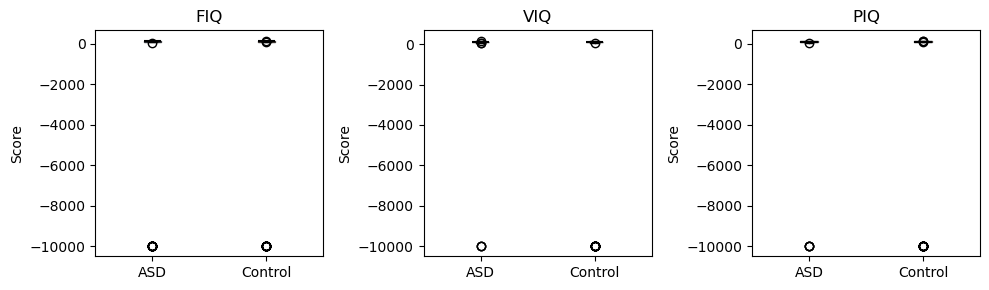

In [6]:
print("IQ by diagnosis:")
print(df.groupby("DX_LABEL")[iq_cols].median().round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, col in zip(axes, iq_cols):
    groups = [grp[col].dropna().values for _, grp in df.groupby("DX_LABEL")]
    labels = df["DX_LABEL"].unique().tolist()
    bp = ax.boxplot(groups, labels=labels, patch_artist=True,
                    medianprops=dict(color="black", linewidth=1.5))
    colors_bp = ["#4C72B0", "#DD8452"]
    for patch, c in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(c)
        patch.set_alpha(0.75)
    ax.set_title(col)
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

## 6. ADOS Total Score Distribution

ADOS_TOTAL: n=392, missing=643 (62.1%)
count     392.00
mean     -525.05
std      2256.88
min     -9999.00
25%         8.00
50%        11.00
75%        14.00
max        22.00


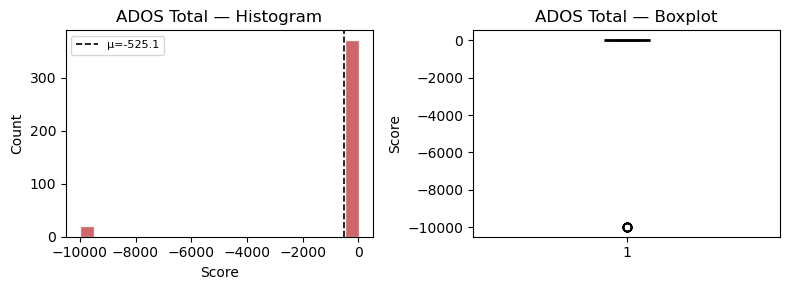

In [7]:
ados = df["ADOS_TOTAL"].dropna()
print(f"ADOS_TOTAL: n={len(ados)}, missing={df['ADOS_TOTAL'].isna().sum()} ({df['ADOS_TOTAL'].isna().mean()*100:.1f}%)")
print(ados.describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].hist(ados, bins=20, color="#C44E52", edgecolor="white", alpha=0.85)
axes[0].axvline(ados.mean(), color="black", linestyle="--", linewidth=1.2, label=f"μ={ados.mean():.1f}")
axes[0].set_title("ADOS Total — Histogram")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Count")
axes[0].legend(fontsize=8)

axes[1].boxplot(ados, vert=True, patch_artist=True,
                boxprops=dict(facecolor="#C44E52", alpha=0.6),
                medianprops=dict(color="black", linewidth=2))
axes[1].set_title("ADOS Total — Boxplot")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

## 7. Cortical Thickness — Overall Distribution

Thickness columns: 68  (lh=34, rh=34)
All values pooled: n=70,364  mean=2.755  std=0.482  min=0.865  max=4.883


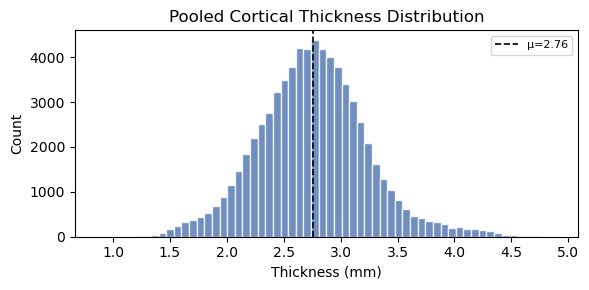

In [8]:
thick_cols = [c for c in df.columns if c.startswith("lh_") or c.startswith("rh_")]
thick_vals = df[thick_cols].values.flatten()
thick_vals = thick_vals[~np.isnan(thick_vals)]

print(f"Thickness columns: {len(thick_cols)}  (lh={sum(c.startswith('lh_') for c in thick_cols)}, rh={sum(c.startswith('rh_') for c in thick_cols)})")
print(f"All values pooled: n={len(thick_vals):,}  mean={thick_vals.mean():.3f}  std={thick_vals.std():.3f}  min={thick_vals.min():.3f}  max={thick_vals.max():.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(thick_vals, bins=60, color="#4C72B0", edgecolor="white", alpha=0.8)
ax.axvline(thick_vals.mean(), color="black", linestyle="--", linewidth=1.2, label=f"μ={thick_vals.mean():.2f}")
ax.set_title("Pooled Cortical Thickness Distribution")
ax.set_xlabel("Thickness (mm)")
ax.set_ylabel("Count")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Thickness Distribution by Diagnosis Group

ASD  thickness: mean=2.751  std=0.481
Ctrl thickness: mean=2.759  std=0.483


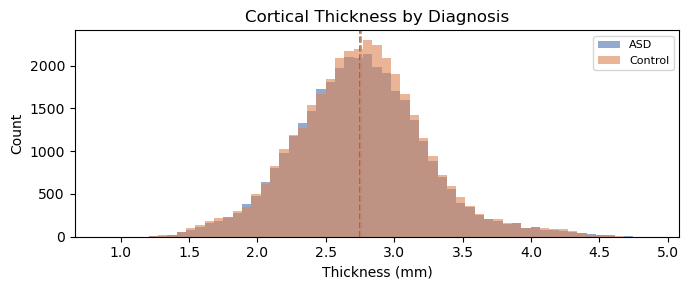

In [14]:
asd_thick = df.loc[df["DX_LABEL"] == "ASD", thick_cols].values.flatten()
tc_thick  = df.loc[df["DX_LABEL"] == "Control", thick_cols].values.flatten()
asd_thick = asd_thick[~np.isnan(asd_thick)]
tc_thick  = tc_thick[~np.isnan(tc_thick)]

print(f"ASD  thickness: mean={asd_thick.mean():.3f}  std={asd_thick.std():.3f}")
print(f"Ctrl thickness: mean={tc_thick.mean():.3f}  std={tc_thick.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(min(asd_thick.min(), tc_thick.min()),
                   max(asd_thick.max(), tc_thick.max()), 60)
ax.hist(asd_thick, bins=bins, alpha=0.6, color="#4C72B0", label="ASD", edgecolor="none")
ax.hist(tc_thick,  bins=bins, alpha=0.6, color="#DD8452", label="Control", edgecolor="none")
ax.axvline(asd_thick.mean(), color="#4C72B0", linestyle="--", linewidth=1.2)
ax.axvline(tc_thick.mean(),  color="#DD8452", linestyle="--", linewidth=1.2)
ax.set_title("Cortical Thickness by Diagnosis")
ax.set_xlabel("Thickness (mm)")
ax.set_ylabel("Count")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Per-Region Mean Thickness (Top 10 Largest Difference ASD vs Control)

Top 10 regions by |ASD - Control| mean thickness:
                        ASD mean  Ctrl mean  |diff|
lh_entorhinal             3.3667     3.4627  0.0961
rh_entorhinal             3.5087     3.5887  0.0800
lh_temporalpole           3.5795     3.6433  0.0638
lh_parahippocampal        2.8777     2.9272  0.0496
rh_lateraloccipital       2.4227     2.3786  0.0441
lh_pericalcarine          1.8212     1.7794  0.0417
rh_caudalmiddlefrontal    2.7088     2.7499  0.0411
lh_lateraloccipital       2.3496     2.3096  0.0399
rh_superiorfrontal        2.9413     2.9797  0.0384
lh_cuneus                 2.0966     2.0594  0.0372


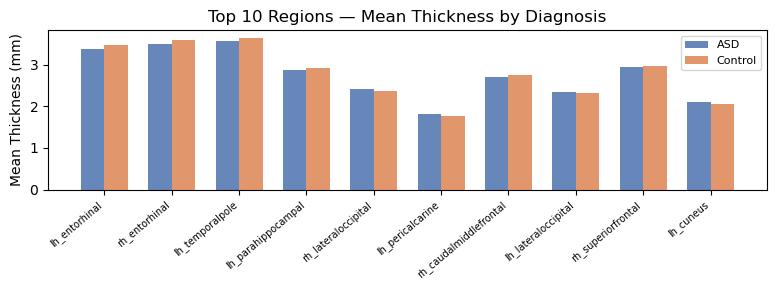

In [15]:
region_means = df.groupby("DX_LABEL")[thick_cols].mean()
diff = (region_means.loc["ASD"] - region_means.loc["Control"]).abs().sort_values(ascending=False)
top10 = diff.head(10)

print("Top 10 regions by |ASD - Control| mean thickness:")
print(pd.DataFrame({
    "ASD mean":  region_means.loc["ASD", top10.index].round(4),
    "Ctrl mean": region_means.loc["Control", top10.index].round(4),
    "|diff|":    top10.round(4)
}).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(top10))
w = 0.35
ax.bar(x - w/2, region_means.loc["ASD", top10.index],  width=w, label="ASD",  color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, region_means.loc["Control", top10.index], width=w, label="Control", color="#DD8452", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(top10.index, rotation=40, ha="right", fontsize=7)
ax.set_title("Top 10 Regions — Mean Thickness by Diagnosis")
ax.set_ylabel("Mean Thickness (mm)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Site Distribution & Sample Count

Samples per site:
DX_LABEL  ASD  Control
SITE_ID               
CALTECH    19       18
CMU        14       13
KKI        20       28
LEUVEN_1   14       15
LEUVEN_2   15       19
MAX_MUN    24       28
NYU        75      100
OHSU       12       14
OLIN       19       15
PITT       29       27
SBL        15       15
SDSU       14       22
STANFORD   19       20
TRINITY    22       25
UCLA_1     41       31
UCLA_2     13       13
UM_1       53       53
UM_2       13       21
USM        46       25
YALE       28       28


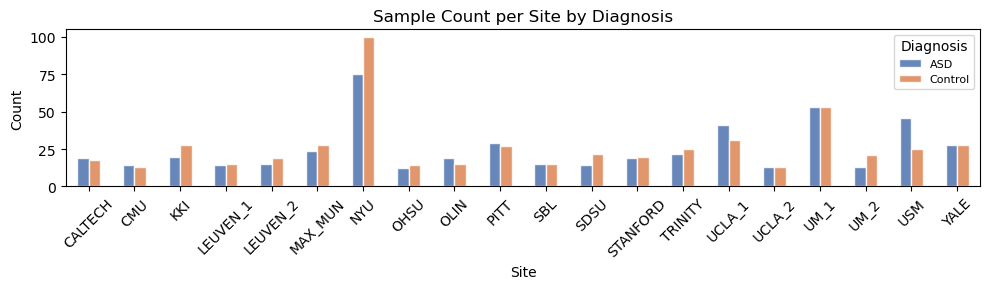

In [16]:
site_counts = df.groupby(["SITE_ID", "DX_LABEL"]).size().unstack(fill_value=0)
print("Samples per site:")
print(site_counts.to_string())

fig, ax = plt.subplots(figsize=(10, 3))
site_counts.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], edgecolor="white", alpha=0.85)
ax.set_title("Sample Count per Site by Diagnosis")
ax.set_xlabel("Site")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Diagnosis", fontsize=8)
plt.tight_layout()
plt.show()

missingdata analysis


Detect hidden missing values (sentinels like -9999)

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("abide_merged.csv")

# Check for sentinel values (-9999, -999, etc.) that are NOT yet NaN
# These are common in ABIDE phenotypic data
print("=" * 60)
print("SENTINEL VALUE DETECTION (before NaN conversion)")
print("=" * 60)

sentinels = [-9999, -999, -1, 999]
numeric_cols = df.select_dtypes(include=[np.number]).columns

for s in sentinels:
    found = (df[numeric_cols] == s).sum()
    found = found[found > 0]
    if len(found) > 0:
        print(f"\nValue {s} found in:")
        print(found.to_string())

# Also check string columns for hidden NA-like tokens
print("\n--- String columns: checking for 'N/A', '-9999', 'none', '' ---")
str_cols = df.select_dtypes(include=["object"]).columns
for c in str_cols:
    weird = df[c].astype(str).str.lower().isin(["n/a", "na", "none", "-9999", "-999", "", "nan"])
    if weird.sum() > 0:
        print(f"{c}: {weird.sum()} suspicious values")
        print(f"  Examples: {df[c][weird].unique()[:5]}")

SENTINEL VALUE DETECTION (before NaN conversion)

Value -9999 found in:
FIQ           35
VIQ           18
PIQ           22
ADOS_TOTAL    21

--- String columns: checking for 'N/A', '-9999', 'none', '' ---
HANDEDNESS_CATEGORY: 286 suspicious values
  Examples: ['-9999' nan]


Convert sentinels to NaN and produce full missing report

In [18]:
# Convert known sentinels to NaN (diagnostic only — does not modify analysis yet)
df_audit = df.copy()
df_audit[["FIQ", "VIQ", "PIQ", "ADOS_TOTAL"]] = df_audit[["FIQ", "VIQ", "PIQ", "ADOS_TOTAL"]].replace(-9999, np.nan)

# Full missing report
missing_report = pd.DataFrame({
    "dtype": df_audit.dtypes.astype(str),
    "n_missing": df_audit.isnull().sum(),
    "pct_missing": (df_audit.isnull().mean() * 100).round(2),
    "n_present": df_audit.notnull().sum()
}).sort_values("pct_missing", ascending=False)

print("=" * 60)
print("FULL MISSING DATA REPORT (all 81 columns)")
print("=" * 60)
print(missing_report.to_string())

print(f"\nColumns with ANY missing: {(missing_report['n_missing'] > 0).sum()}")
print(f"Columns fully complete:  {(missing_report['n_missing'] == 0).sum()}")

FULL MISSING DATA REPORT (all 81 columns)
                               dtype  n_missing  pct_missing  n_present
ADOS_TOTAL                   float64        664        64.15        371
HANDEDNESS_CATEGORY           object        276        26.67        759
VIQ                          float64        179        17.29        856
PIQ                          float64        165        15.94        870
FIQ                          float64         69         6.67        966
rh_posteriorcingulate        float64          2         0.19       1033
rh_pericalcarine             float64          1         0.10       1034
rh_fusiform                  float64          1         0.10       1034
lh_medialorbitofrontal       float64          1         0.10       1034
lh_transversetemporal        float64          1         0.10       1034
lh_isthmuscingulate          float64          1         0.10       1034
lh_rostralanteriorcingulate  float64          1         0.10       1034
rh_rostralanteriorcing

Visualize missing counts (only columns with missing data)


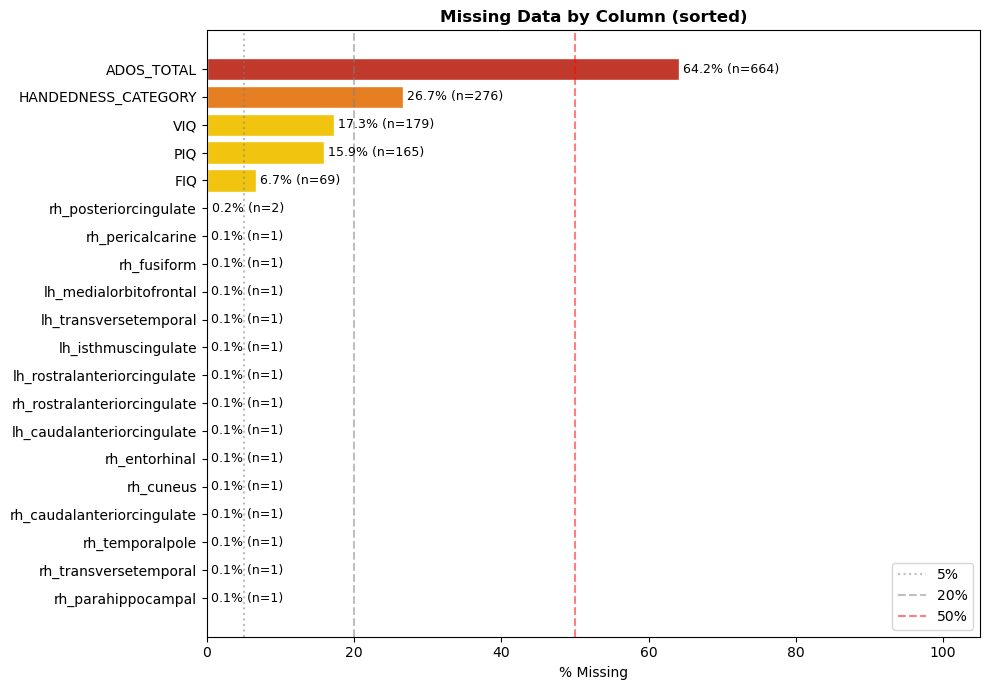

In [19]:
# Keep only columns that actually have missing values
miss_plot = missing_report[missing_report["n_missing"] > 0].copy()

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(miss_plot))))
colors = ["#C0392B" if p > 50 else "#E67E22" if p > 20 else "#F1C40F" if p > 5 else "#95A5A6"
          for p in miss_plot["pct_missing"]]

ax.barh(miss_plot.index, miss_plot["pct_missing"], color=colors, edgecolor="white")
ax.set_xlabel("% Missing")
ax.set_title("Missing Data by Column (sorted)", fontsize=12, fontweight="bold")
ax.invert_yaxis()

# Add count labels
for i, (pct, n) in enumerate(zip(miss_plot["pct_missing"], miss_plot["n_missing"])):
    ax.text(pct + 0.5, i, f"{pct:.1f}% (n={n})", va="center", fontsize=9)

ax.axvline(5, color="gray", linestyle=":", alpha=0.5, label="5%")
ax.axvline(20, color="gray", linestyle="--", alpha=0.5, label="20%")
ax.axvline(50, color="red", linestyle="--", alpha=0.5, label="50%")
ax.legend(loc="lower right")
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

Site × Column missingness matrix (the critical one)


MISSING % per Site × Column (phenotypic)
          n_subjects  AGE_AT_SCAN  SEX    FIQ    VIQ    PIQ  ADOS_TOTAL  HANDEDNESS_CATEGORY
SITE_ID                                                                                     
CALTECH           37          0.0  0.0    2.7    2.7    2.7        48.6                  0.0
CMU               27          0.0  0.0    0.0    0.0    0.0        48.1                  0.0
KKI               48          0.0  0.0    0.0  100.0  100.0        58.3                  0.0
LEUVEN_1          29          0.0  0.0    0.0    0.0    0.0       100.0                  0.0
LEUVEN_2          34          0.0  0.0  100.0    0.0    0.0       100.0                  0.0
MAX_MUN           52          0.0  0.0    3.8  100.0   63.5        88.5                  0.0
NYU              175          0.0  0.0    0.0    0.0    0.0        57.1                100.0
OHSU              26          0.0  0.0    3.8  100.0  100.0        53.8                  0.0
OLIN              34         

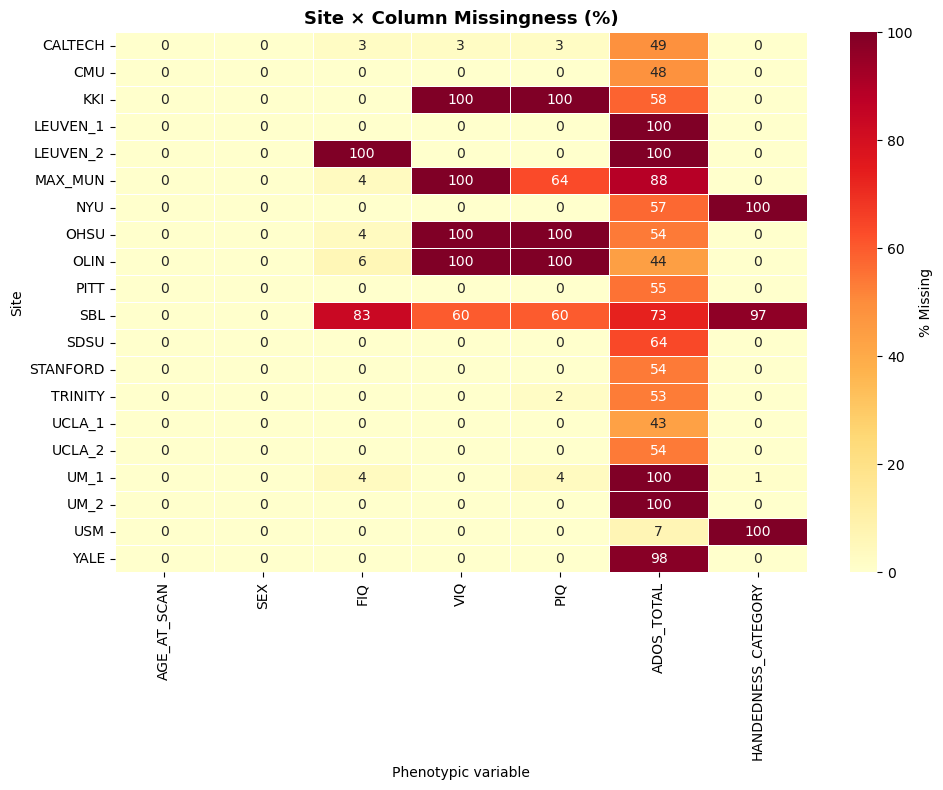

In [20]:
# Focus on phenotypic columns first
PHENO_COLS = ["AGE_AT_SCAN", "SEX", "FIQ", "VIQ", "PIQ", "ADOS_TOTAL", "HANDEDNESS_CATEGORY"]

# Compute % missing per site per column
site_miss_pct = df_audit.groupby("SITE_ID")[PHENO_COLS].apply(
    lambda g: g.isnull().mean() * 100
).round(1)

# Also compute subject counts per site for context
site_n = df_audit.groupby("SITE_ID").size().rename("n_subjects")

print("=" * 60)
print("MISSING % per Site × Column (phenotypic)")
print("=" * 60)
print(pd.concat([site_n, site_miss_pct], axis=1).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    site_miss_pct,
    annot=True, fmt=".0f",
    cmap="YlOrRd", vmin=0, vmax=100,
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "% Missing"},
    ax=ax
)
ax.set_title("Site × Column Missingness (%)", fontsize=13, fontweight="bold")
ax.set_xlabel("Phenotypic variable")
ax.set_ylabel("Site")
plt.tight_layout()
plt.show()

Which sites dropped which column entirely (100% missing)?

In [21]:
# Identify site/column combinations with 100% missing — the site simply never collected that variable
fully_missing = site_miss_pct[site_miss_pct == 100].stack()
print("=" * 60)
print("SITE × COLUMN — 100% MISSING (site never provided this variable)")
print("=" * 60)
if len(fully_missing) > 0:
    for (site, col), val in fully_missing.items():
        print(f"  {site:12s} → {col} : completely missing")
else:
    print("No site has any variable 100% missing.")

# Partial missing (>50% but <100%) — also suspicious
partial = site_miss_pct[(site_miss_pct > 50) & (site_miss_pct < 100)].stack()
print("\n" + "=" * 60)
print("SITE × COLUMN — >50% but <100% MISSING (suspicious)")
print("=" * 60)
if len(partial) > 0:
    for (site, col), val in partial.items():
        print(f"  {site:12s} → {col:22s} : {val:.0f}% missing")
else:
    print("None.")

SITE × COLUMN — 100% MISSING (site never provided this variable)
  KKI          → VIQ : completely missing
  KKI          → PIQ : completely missing
  LEUVEN_1     → ADOS_TOTAL : completely missing
  LEUVEN_2     → FIQ : completely missing
  LEUVEN_2     → ADOS_TOTAL : completely missing
  MAX_MUN      → VIQ : completely missing
  NYU          → HANDEDNESS_CATEGORY : completely missing
  OHSU         → VIQ : completely missing
  OHSU         → PIQ : completely missing
  OLIN         → VIQ : completely missing
  OLIN         → PIQ : completely missing
  UM_1         → ADOS_TOTAL : completely missing
  UM_2         → ADOS_TOTAL : completely missing
  USM          → HANDEDNESS_CATEGORY : completely missing

SITE × COLUMN — >50% but <100% MISSING (suspicious)
  KKI          → ADOS_TOTAL             : 58% missing
  MAX_MUN      → PIQ                    : 64% missing
  MAX_MUN      → ADOS_TOTAL             : 88% missing
  NYU          → ADOS_TOTAL             : 57% missing
  OHSU         → A

Row-level missingness: how many columns missing per subject?

ROW-LEVEL MISSINGNESS (per subject)
count    1035.00
mean        1.32
std         0.97
min         0.00
25%         1.00
50%         1.00
75%         2.00
max         5.00

Subjects with 0 missing values: 162
Subjects with ≥1 missing:        873
Subjects with ≥5 missing:        19
Subjects with ≥10 missing:       0


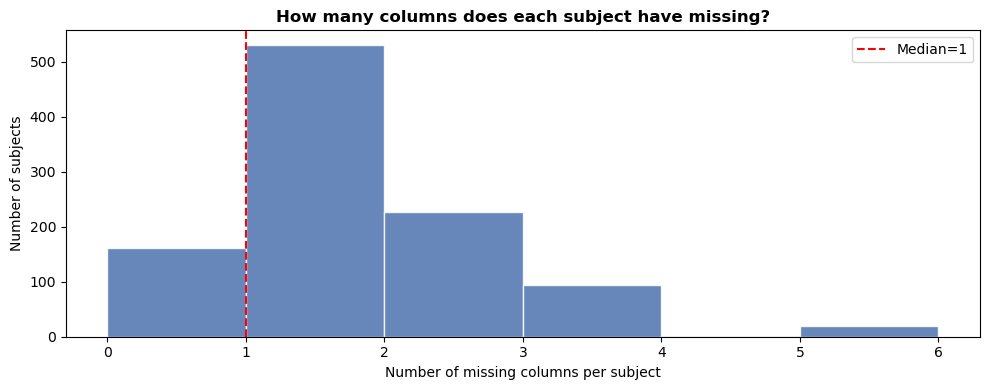

In [22]:
# How many values are missing per subject (across all 81 columns)
row_missing = df_audit.isnull().sum(axis=1)

print("=" * 60)
print("ROW-LEVEL MISSINGNESS (per subject)")
print("=" * 60)
print(row_missing.describe().round(2).to_string())
print(f"\nSubjects with 0 missing values: {(row_missing == 0).sum()}")
print(f"Subjects with ≥1 missing:        {(row_missing >= 1).sum()}")
print(f"Subjects with ≥5 missing:        {(row_missing >= 5).sum()}")
print(f"Subjects with ≥10 missing:       {(row_missing >= 10).sum()}")

# Histogram
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(row_missing, bins=range(0, int(row_missing.max()) + 2),
        color="#4C72B0", edgecolor="white", alpha=0.85)
ax.set_xlabel("Number of missing columns per subject")
ax.set_ylabel("Number of subjects")
ax.set_title("How many columns does each subject have missing?", fontsize=12, fontweight="bold")
ax.axvline(row_missing.median(), color="red", linestyle="--", label=f"Median={row_missing.median():.0f}")
ax.legend()
plt.tight_layout()
plt.show()

Missing co-occurrence: do columns miss TOGETHER?

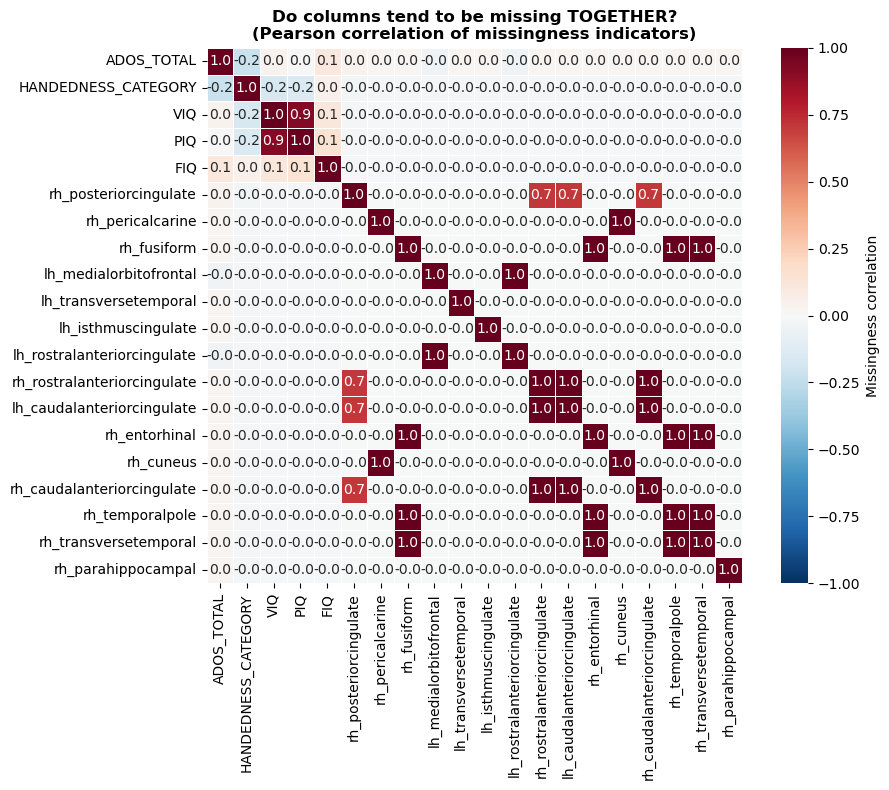


--- Column pairs that miss together (|r| > 0.5) ---
  rh_pericalcarine       ↔ rh_cuneus              : r = 1.00
  rh_fusiform            ↔ rh_entorhinal          : r = 1.00
  rh_fusiform            ↔ rh_temporalpole        : r = 1.00
  rh_fusiform            ↔ rh_transversetemporal  : r = 1.00
  lh_medialorbitofrontal ↔ lh_rostralanteriorcingulate : r = 1.00
  rh_rostralanteriorcingulate ↔ lh_caudalanteriorcingulate : r = 1.00
  rh_rostralanteriorcingulate ↔ rh_caudalanteriorcingulate : r = 1.00
  lh_caudalanteriorcingulate ↔ rh_caudalanteriorcingulate : r = 1.00
  rh_entorhinal          ↔ rh_temporalpole        : r = 1.00
  rh_entorhinal          ↔ rh_transversetemporal  : r = 1.00
  rh_temporalpole        ↔ rh_transversetemporal  : r = 1.00
  VIQ                    ↔ PIQ                    : r = 0.92
  rh_posteriorcingulate  ↔ rh_rostralanteriorcingulate : r = 0.71
  rh_posteriorcingulate  ↔ lh_caudalanteriorcingulate : r = 0.71
  rh_posteriorcingulate  ↔ rh_caudalanteriorcingulate

In [24]:
# Only look at columns that have missing values
cols_with_missing = missing_report[missing_report["n_missing"] > 0].index.tolist()

# Build missing indicator matrix (1 = missing, 0 = present)
miss_indicator = df_audit[cols_with_missing].isnull().astype(int)

# Correlation of missingness: if two columns tend to be missing together, correlation is high
miss_corr = miss_indicator.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    miss_corr,
    annot=True, fmt=".1f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    linewidths=0.5, square=True,
    cbar_kws={"label": "Missingness correlation"},
    ax=ax
)
ax.set_title("Do columns tend to be missing TOGETHER?\n(Pearson correlation of missingness indicators)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Print strong co-occurrences
print("\n--- Column pairs that miss together (|r| > 0.5) ---")
pairs = []
for i, c1 in enumerate(miss_corr.columns):
    for c2 in miss_corr.columns[i+1:]:
        r = miss_corr.loc[c1, c2]
        if abs(r) > 0.5:
            pairs.append((c1, c2, r))
for c1, c2, r in sorted(pairs, key=lambda x: -abs(x[2])):
    print(f"  {c1:22s} ↔ {c2:22s} : r = {r:.2f}")

Missing in thickness columns: which regions, which subjects?


In [25]:
THICKNESS_COLS = [c for c in df_audit.columns if c.startswith(("lh_", "rh_"))]

# Per-region missing counts
region_miss = df_audit[THICKNESS_COLS].isnull().sum()
region_miss = region_miss[region_miss > 0].sort_values(ascending=False)

print("=" * 60)
print("THICKNESS COLUMNS WITH MISSING VALUES")
print("=" * 60)
if len(region_miss) > 0:
    print(region_miss.to_string())
else:
    print("All thickness columns are fully present.")

# Which subjects are missing at least one thickness value?
subj_with_thick_miss = df_audit[df_audit[THICKNESS_COLS].isnull().any(axis=1)]
print(f"\nSubjects missing ≥1 thickness value: {len(subj_with_thick_miss)}")
if len(subj_with_thick_miss) > 0:
    print("\nThese subjects (SUB_ID, SITE_ID, DX_LABEL, # missing regions):")
    info = subj_with_thick_miss[["SUB_ID", "SITE_ID", "DX_LABEL"]].copy()
    info["n_missing_regions"] = subj_with_thick_miss[THICKNESS_COLS].isnull().sum(axis=1).values
    print(info.to_string(index=False))

THICKNESS COLUMNS WITH MISSING VALUES
rh_posteriorcingulate          2
lh_caudalanteriorcingulate     1
lh_isthmuscingulate            1
lh_medialorbitofrontal         1
lh_rostralanteriorcingulate    1
lh_transversetemporal          1
rh_caudalanteriorcingulate     1
rh_cuneus                      1
rh_entorhinal                  1
rh_fusiform                    1
rh_parahippocampal             1
rh_pericalcarine               1
rh_rostralanteriorcingulate    1
rh_temporalpole                1
rh_transversetemporal          1

Subjects missing ≥1 thickness value: 8

These subjects (SUB_ID, SITE_ID, DX_LABEL, # missing regions):
 SUB_ID  SITE_ID DX_LABEL  n_missing_regions
  50272     UM_1      ASD                  1
  50274     UM_1      ASD                  1
  50277     UM_1      ASD                  1
  50283     UM_1      ASD                  2
  50288     UM_1      ASD                  4
  50327     UM_1  Control                  4
  51190 STANFORD  Control                  1
  5

 Is missingness biased by diagnosis group?

MISSING % by Diagnosis Group
          FIQ   VIQ   PIQ  ADOS_TOTAL  HANDEDNESS_CATEGORY
DX_LABEL                                                  
ASD       6.3  15.6  15.2        30.5                 26.9
Control   7.0  18.9  16.6        96.2                 26.4


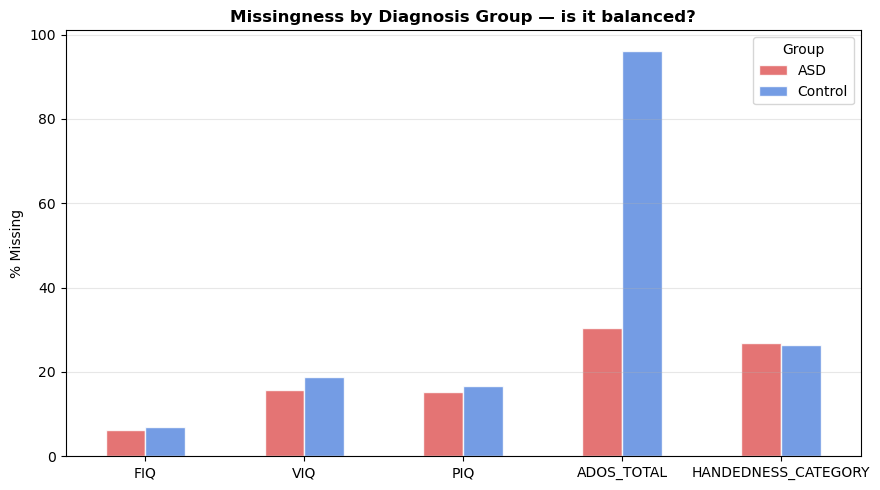


--- Chi-square test: is missingness independent of diagnosis? ---
  FIQ                    χ² =   0.08  p = 0.7712  [ok]
  VIQ                    χ² =   1.66  p = 0.1975  [ok]
  PIQ                    χ² =   0.26  p = 0.6095  [ok]
  ADOS_TOTAL             χ² = 483.01  p = 0.0000  [⚠ BIASED]
  HANDEDNESS_CATEGORY    χ² =   0.01  p = 0.9067  [ok]


In [26]:
# Compare % missing per column between ASD and Control
# If an ASD patient is MORE LIKELY to be missing a value, this is MNAR bias
check_cols = ["FIQ", "VIQ", "PIQ", "ADOS_TOTAL", "HANDEDNESS_CATEGORY"]

dx_miss = df_audit.groupby("DX_LABEL")[check_cols].apply(
    lambda g: g.isnull().mean() * 100
).round(1)

print("=" * 60)
print("MISSING % by Diagnosis Group")
print("=" * 60)
print(dx_miss.to_string())

# Visualize as grouped bar chart
dx_miss_T = dx_miss.T  # columns = ASD / Control, rows = variables
fig, ax = plt.subplots(figsize=(9, 5))
dx_miss_T.plot(kind="bar", ax=ax, color=["#E05C5C", "#5C8BE0"],
               edgecolor="white", alpha=0.85)
ax.set_ylabel("% Missing")
ax.set_title("Missingness by Diagnosis Group — is it balanced?",
             fontsize=12, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Group")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Quick chi-square to test if missingness is independent of diagnosis
from scipy.stats import chi2_contingency
print("\n--- Chi-square test: is missingness independent of diagnosis? ---")
for col in check_cols:
    tbl = pd.crosstab(df_audit["DX_LABEL"], df_audit[col].isnull())
    if tbl.shape == (2, 2):
        chi2, p, _, _ = chi2_contingency(tbl)
        flag = "⚠ BIASED" if p < 0.05 else "ok"
        print(f"  {col:22s} χ² = {chi2:6.2f}  p = {p:.4f}  [{flag}]")